# Modeling: Who Seeks Treatment?
Predicts `treatment` (sought mental-health treatment: Yes/No) from the cleaned OSMI 2014 survey.

**Two models, on purpose.** `work_interfere` ("If you have a condition, does it interfere with your work?") almost gives away the answer, so we report both:
- **Model B (headline):** no `work_interfere`, all 1,259 respondents.
- **Model A (association-aware):** with `work_interfere`, only the 995 respondents who answered it. The 264 "Unknown" rows are dropped, because skipping the question is itself a near-perfect signal of "No".

**Protocol:** stratified 80/20 split (seed 42). Model comparison and tuning use 5-fold cross-validation repeated on the 80% training part only. The 20% test set is scored once, at the end, for the chosen model.

## 1. Setup

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay, RocCurveDisplay, accuracy_score, confusion_matrix,
    classification_report, f1_score, precision_score, recall_score, roc_auc_score,
)
from sklearn.model_selection import (
    GridSearchCV, RepeatedStratifiedKFold, cross_validate, train_test_split,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

SEED = 42
SCORING = {"auc": "roc_auc", "f1": "f1", "recall": "recall",
           "precision": "precision", "accuracy": "accuracy"}

## 2. Feature preparation
Rules agreed after the EDA:
- **Dropped:** `Timestamp`, `Gender_raw`, `Country`, `Country_grouped`, `state`. Country is significantly but only weakly associated with treatment and added nothing in cross-validation (AUC 0.769 vs 0.768). `Timestamp` and the raw/free-text columns are not features.
- **Gender:** "Non-binary/Other" and "Unknown" merged into "Other" (n = 18). Kept as a category, but no metrics are reported for this group alone.
- **Ordered scales:** `no_employees` coded 0–5 in its real order; `work_interfere` coded 0–3 (Never < Rarely < Sometimes < Often).
- **"Don't know" / "Not sure"** stay as their own answer category.
- Everything else is one-hot encoded inside the pipeline, so nothing is learned from the test set.

In [2]:
df = pd.read_csv("../data/processed/survey_clean.csv")

y = (df["treatment"] == "Yes").astype(int)
df = df.drop(columns=["Timestamp", "Gender_raw", "Country", "Country_grouped", "state", "treatment"])

df["Gender"] = df["Gender"].replace({"Non-binary/Other": "Other", "Unknown": "Other"})

size_order = ["1-5", "6-25", "26-100", "100-500", "500-1000", "More than 1000"]
df["no_employees"] = df["no_employees"].map({s: i for i, s in enumerate(size_order)})
assert df["no_employees"].notna().all()

# Model B: all respondents, no work_interfere
X_B, y_B = df.drop(columns="work_interfere"), y

# Model A: only respondents who answered work_interfere
answered = df["work_interfere"] != "Unknown"
X_A, y_A = df[answered].copy(), y[answered]
X_A["work_interfere"] = X_A["work_interfere"].map({"Never": 0, "Rarely": 1, "Sometimes": 2, "Often": 3})
assert X_A["work_interfere"].notna().all()

for name, X, t in [("Model B", X_B, y_B), ("Model A", X_A, y_A)]:
    print(f"{name}: {X.shape[0]} rows, {X.shape[1]} features, {t.mean():.1%} sought treatment")

Model B: 1259 rows, 21 features, 50.6% sought treatment
Model A: 995 rows, 22 features, 63.6% sought treatment


## 3. Experiment helper
One function runs the whole protocol so Model A and Model B are treated identically:
1. stratified 80/20 split; 2. majority-class baseline; 3. repeated 5×10 CV of three default models; 4. small grid search per model (5×3 repeated CV); 5. pick the best tuned model by CV AUC; 6. score the test set once.

In [3]:
NUMERIC = ["Age", "no_employees", "work_interfere"]


def make_pipeline(X, model):
    numeric = [c for c in NUMERIC if c in X.columns]
    nominal = [c for c in X.columns if c not in numeric]
    prep = ColumnTransformer([
        ("num", StandardScaler(), numeric),
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), nominal),
    ])
    return Pipeline([("prep", prep), ("model", model)])


def default_models():
    return {
        "Logistic regression": LogisticRegression(max_iter=2000),
        "Random forest": RandomForestClassifier(n_estimators=300, min_samples_leaf=3, random_state=SEED, n_jobs=-1),
        "Gradient boosting": HistGradientBoostingClassifier(max_iter=100, random_state=SEED),
    }


GRIDS = {
    "Logistic regression": {"model__C": [0.01, 0.03, 0.1, 0.3, 1, 3]},
    "Random forest": {"model__max_depth": [4, 8, None], "model__min_samples_leaf": [3, 8]},
    "Gradient boosting": {"model__learning_rate": [0.03, 0.1], "model__max_leaf_nodes": [4, 8]},
}


def cv_summary(pipe, X, y, cv):
    r = cross_validate(pipe, X, y, cv=cv, scoring=SCORING, n_jobs=-1)
    return {m: f"{r['test_' + m].mean():.3f} ± {r['test_' + m].std():.3f}" for m in SCORING}


def run_experiment(X, y):
    X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, stratify=y, random_state=SEED)
    cv_full = RepeatedStratifiedKFold(n_splits=5, n_repeats=10, random_state=SEED)
    cv_tune = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=SEED)
    out = {"X_tr": X_tr, "X_te": X_te, "y_tr": y_tr, "y_te": y_te}

    rows = {"Majority-class baseline": cv_summary(
        make_pipeline(X, DummyClassifier(strategy="most_frequent")), X_tr, y_tr, cv_full)}
    for name, model in default_models().items():
        rows[name + " (default)"] = cv_summary(make_pipeline(X, model), X_tr, y_tr, cv_full)
    out["cv_default"] = pd.DataFrame(rows).T

    tuned, rows = {}, {}
    for name, model in default_models().items():
        gs = GridSearchCV(make_pipeline(X, model), GRIDS[name], cv=cv_tune, scoring="roc_auc", n_jobs=-1)
        gs.fit(X_tr, y_tr)
        tuned[name] = gs.best_estimator_
        rows[name + " (tuned)"] = {"best params": {k.split("__")[1]: v for k, v in gs.best_params_.items()},
                                   "cv AUC": round(gs.best_score_, 3)}
    out["tuned"] = tuned
    out["cv_tuned"] = pd.DataFrame(rows).T
    out["best_name"] = max(rows, key=lambda k: rows[k]["cv AUC"]).replace(" (tuned)", "")
    return out


def test_scores(pipe, X_te, y_te):
    proba = pipe.predict_proba(X_te)[:, 1]
    pred = (proba >= 0.5).astype(int)
    return {"AUC": roc_auc_score(y_te, proba), "F1": f1_score(y_te, pred),
            "Recall": recall_score(y_te, pred), "Precision": precision_score(y_te, pred),
            "Accuracy": accuracy_score(y_te, pred)}


def show_reports(res):
    """Print sklearn classification reports (train and test) for every tuned model."""
    for name, pipe in res["tuned"].items():
        for split in ("train", "test"):
            X_s, y_s = (res["X_tr"], res["y_tr"]) if split == "train" else (res["X_te"], res["y_te"])
            print(f"=== {name} ({split}, n={len(y_s)}) ===")
            print(classification_report(y_s, pipe.predict(X_s), target_names=["No treatment", "Sought treatment"], digits=3))

## 4. Model B (headline): without `work_interfere`
### 4.1 Cross-validated comparison on the training set (mean ± SD over 50 folds)

In [4]:
res_B = run_experiment(X_B, y_B)
print("Train rows:", len(res_B["X_tr"]), "| Test rows:", len(res_B["X_te"]))
res_B["cv_default"]

Train rows: 1007 | Test rows: 252


,auc,f1,recall,precision,accuracy
Majority-class baseline,0.500 ± 0.000,0.672 ± 0.002,1.000 ± 0.000,0.505 ± 0.002,0.505 ± 0.002
Logistic regression (default),0.771 ± 0.030,0.708 ± 0.029,0.701 ± 0.041,0.717 ± 0.028,0.709 ± 0.027
Random forest (default),0.782 ± 0.028,0.732 ± 0.030,0.740 ± 0.046,0.726 ± 0.029,0.727 ± 0.027
Gradient boosting (default),0.750 ± 0.030,0.696 ± 0.031,0.699 ± 0.048,0.695 ± 0.027,0.693 ± 0.027


### 4.2 Tuned models

In [5]:
res_B["cv_tuned"]

,best params,cv AUC
Logistic regression (tuned),{'C': 0.03},0.776
Random forest (tuned),"{'max_depth': 8, 'min_samples_leaf': 3}",0.784
Gradient boosting (tuned),"{'learning_rate': 0.03, 'max_leaf_nodes': 4}",0.777


In [6]:
print("Best by CV AUC:", res_B["best_name"])

Best by CV AUC: Random forest


### 4.3 Test set (scored once)
All three tuned models are shown for context; the one chosen above by cross-validation is the model we would report.

In [7]:
test_B = pd.DataFrame({n: test_scores(m, res_B["X_te"], res_B["y_te"]) for n, m in res_B["tuned"].items()}).T
test_B.round(3)

,AUC,F1,Recall,Precision,Accuracy
Logistic regression,0.762,0.700,0.664,0.739,0.710
Random forest,0.751,0.688,0.672,0.705,0.690
Gradient boosting,0.742,0.696,0.680,0.713,0.698


### 4.4 Classification reports (easier-to-read version of the table above)
For each tuned model: **precision** = of the people it called "Yes", how many really were; **recall** = of the real "Yes" people, how many it found; **f1** mixes the two; **support** = number of people. "train" is the data the model learned from, "test" is the hidden final exam.

In [8]:
show_reports(res_B)

=== Logistic regression (train, n=1007) ===
                  precision    recall  f1-score   support

    No treatment      0.735     0.735     0.735       498
Sought treatment      0.741     0.741     0.741       509

        accuracy                          0.738      1007
       macro avg      0.738     0.738     0.738      1007
    weighted avg      0.738     0.738     0.738      1007

=== Logistic regression (test, n=252) ===
                  precision    recall  f1-score   support

    No treatment      0.686     0.758     0.720       124
Sought treatment      0.739     0.664     0.700       128

        accuracy                          0.710       252
       macro avg      0.713     0.711     0.710       252
    weighted avg      0.713     0.710     0.710       252

=== Random forest (train, n=1007) ===


                  precision    recall  f1-score   support

    No treatment      0.819     0.809     0.814       498
Sought treatment      0.816     0.825     0.820       509

        accuracy                          0.817      1007
       macro avg      0.817     0.817     0.817      1007
    weighted avg      0.817     0.817     0.817      1007

=== Random forest (test, n=252) ===


                  precision    recall  f1-score   support

    No treatment      0.677     0.710     0.693       124
Sought treatment      0.705     0.672     0.688       128

        accuracy                          0.690       252
       macro avg      0.691     0.691     0.690       252
    weighted avg      0.691     0.690     0.690       252

=== Gradient boosting (train, n=1007) ===
                  precision    recall  f1-score   support

    No treatment      0.749     0.713     0.730       498
Sought treatment      0.732     0.766     0.749       509

        accuracy                          0.740      1007
       macro avg      0.740     0.740     0.740      1007
    weighted avg      0.740     0.740     0.740      1007

=== Gradient boosting (test, n=252) ===
                  precision    recall  f1-score   support

    No treatment      0.685     0.718     0.701       124
Sought treatment      0.713     0.680     0.696       128

        accuracy                        

## 5. Model A: with `work_interfere` (respondents who answered it)

In [9]:
res_A = run_experiment(X_A, y_A)
print("Train rows:", len(res_A["X_tr"]), "| Test rows:", len(res_A["X_te"]))
display(res_A["cv_default"])
display(res_A["cv_tuned"])
print("Best by CV AUC:", res_A["best_name"])
test_A = pd.DataFrame({n: test_scores(m, res_A["X_te"], res_A["y_te"]) for n, m in res_A["tuned"].items()}).T
test_A.round(3)

Train rows: 796 | Test rows: 199


,auc,f1,recall,precision,accuracy
Majority-class baseline,0.500 ± 0.000,0.777 ± 0.001,1.000 ± 0.000,0.636 ± 0.001,0.636 ± 0.001
Logistic regression (default),0.828 ± 0.032,0.838 ± 0.027,0.874 ± 0.037,0.807 ± 0.028,0.786 ± 0.034
Random forest (default),0.829 ± 0.029,0.837 ± 0.019,0.903 ± 0.028,0.780 ± 0.024,0.776 ± 0.027
Gradient boosting (default),0.808 ± 0.033,0.826 ± 0.025,0.858 ± 0.035,0.798 ± 0.027,0.771 ± 0.032


,best params,cv AUC
Logistic regression (tuned),{'C': 0.03},0.833
Random forest (tuned),"{'max_depth': 4, 'min_samples_leaf': 3}",0.832
Gradient boosting (tuned),"{'learning_rate': 0.03, 'max_leaf_nodes': 4}",0.838


Best by CV AUC: Gradient boosting


,AUC,F1,Recall,Precision,Accuracy
Logistic regression,0.800,0.822,0.874,0.776,0.759
Random forest,0.802,0.815,0.882,0.757,0.744
Gradient boosting,0.815,0.836,0.906,0.777,0.774


### 5.1 Classification reports (Model A)

In [10]:
show_reports(res_A)

=== Logistic regression (train, n=796) ===
                  precision    recall  f1-score   support

    No treatment      0.822     0.621     0.707       290
Sought treatment      0.809     0.923     0.862       506

        accuracy                          0.813       796
       macro avg      0.816     0.772     0.785       796
    weighted avg      0.814     0.813     0.806       796

=== Logistic regression (test, n=199) ===
                  precision    recall  f1-score   support

    No treatment      0.714     0.556     0.625        72
Sought treatment      0.776     0.874     0.822       127

        accuracy                          0.759       199
       macro avg      0.745     0.715     0.724       199
    weighted avg      0.754     0.759     0.751       199

=== Random forest (train, n=796) ===


                  precision    recall  f1-score   support

    No treatment      0.870     0.531     0.660       290
Sought treatment      0.780     0.955     0.859       506

        accuracy                          0.800       796
       macro avg      0.825     0.743     0.759       796
    weighted avg      0.813     0.800     0.786       796

=== Random forest (test, n=199) ===


                  precision    recall  f1-score   support

    No treatment      0.706     0.500     0.585        72
Sought treatment      0.757     0.882     0.815       127

        accuracy                          0.744       199
       macro avg      0.731     0.691     0.700       199
    weighted avg      0.738     0.744     0.732       199

=== Gradient boosting (train, n=796) ===
                  precision    recall  f1-score   support

    No treatment      0.856     0.576     0.689       290
Sought treatment      0.795     0.945     0.864       506

        accuracy                          0.810       796
       macro avg      0.826     0.760     0.776       796
    weighted avg      0.818     0.810     0.800       796

=== Gradient boosting (test, n=199) ===
                  precision    recall  f1-score   support

    No treatment      0.765     0.542     0.634        72
Sought treatment      0.777     0.906     0.836       127

        accuracy                         

## 6. Chosen models: ROC curves and confusion matrices on the test set

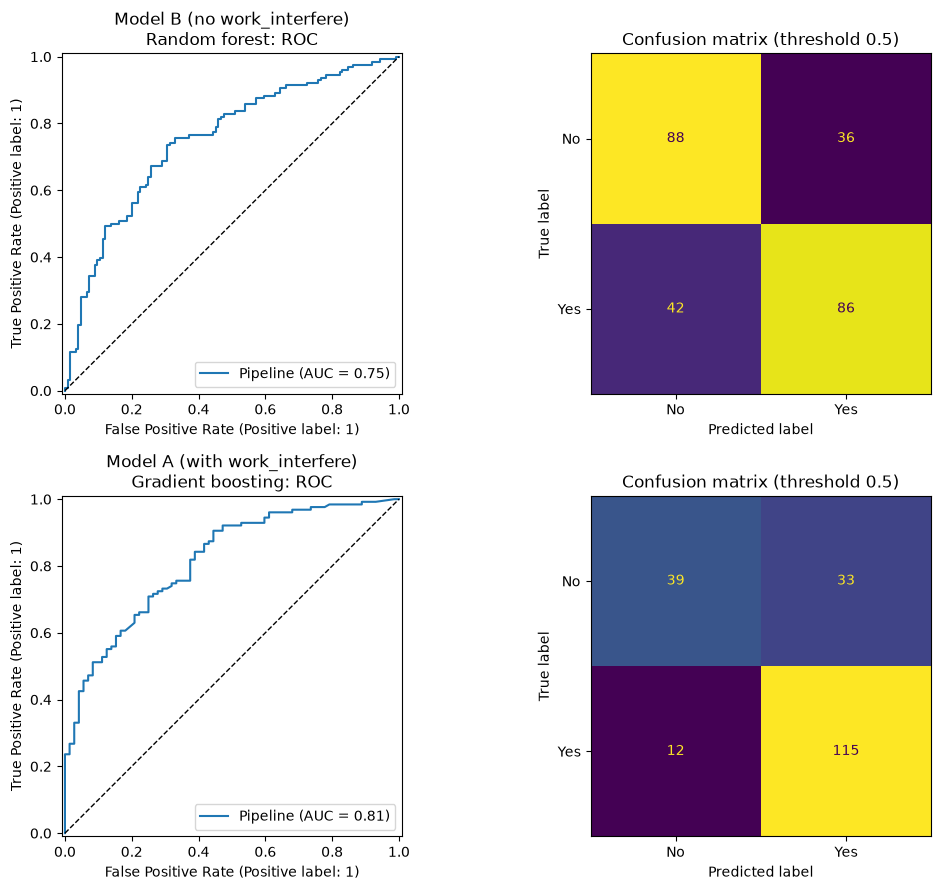

In [11]:
fig, axes = plt.subplots(2, 2, figsize=(11, 9))
for row, (label, res) in enumerate([("Model B (no work_interfere)", res_B), ("Model A (with work_interfere)", res_A)]):
    pipe = res["tuned"][res["best_name"]]
    RocCurveDisplay.from_estimator(pipe, res["X_te"], res["y_te"], ax=axes[row, 0])
    axes[row, 0].plot([0, 1], [0, 1], "k--", lw=1)
    axes[row, 0].set_title(f"{label}\n{res['best_name']}: ROC")
    ConfusionMatrixDisplay.from_estimator(pipe, res["X_te"], res["y_te"], ax=axes[row, 1],
                                          display_labels=["No", "Yes"], colorbar=False)
    axes[row, 1].set_title("Confusion matrix (threshold 0.5)")
plt.tight_layout()
plt.show()

## 7. Interpretation (Model B)
### 7.1 Logistic regression odds ratios
Odds ratios above 1 mean higher odds of having sought treatment, holding the other features fixed. Numeric features are standardized, so their ratio is per 1 standard deviation. These are associations, not causes.

In [12]:
lr_B = res_B["tuned"]["Logistic regression"]
names = lr_B.named_steps["prep"].get_feature_names_out()
coefs = pd.Series(lr_B.named_steps["model"].coef_[0], index=names)
odds = np.exp(coefs).rename("odds ratio").round(2)
pd.concat([odds.sort_values(ascending=False).head(10), odds.sort_values().head(10)]).to_frame()

,odds ratio
cat__family_history_Yes,1.81
cat__care_options_Yes,1.45
cat__coworkers_Yes,1.29
cat__benefits_Yes,1.26
cat__Gender_Female,1.22
cat__leave_Somewhat difficult,1.19
cat__obs_consequence_Yes,1.17
cat__leave_Very difficult,1.17
cat__anonymity_Yes,1.14
cat__mental_health_consequence_Yes,1.14


### 7.2 Permutation importance (test set, drop in AUC when a feature is shuffled)

In [13]:
best_B = res_B["tuned"][res_B["best_name"]]
pi = permutation_importance(best_B, res_B["X_te"], res_B["y_te"], scoring="roc_auc",
                            n_repeats=30, random_state=SEED, n_jobs=-1)
imp = pd.DataFrame({"mean": pi.importances_mean, "sd": pi.importances_std}, index=res_B["X_te"].columns)
imp = imp.sort_values("mean", ascending=False)
print("Model:", res_B["best_name"])
imp.round(4).head(10)

Model: Random forest


,mean,sd
family_history,0.1072,0.0275
care_options,0.0313,0.0151
Gender,0.0180,0.0080
benefits,0.0140,0.0063
obs_consequence,0.0073,0.0059
coworkers,0.0060,0.0037
mental_health_interview,0.0040,0.0022
no_employees,0.0033,0.0023
leave,0.0025,0.0073
phys_health_interview,0.0021,0.0025


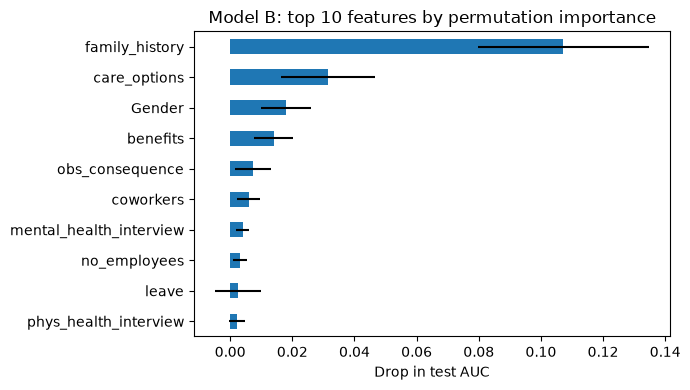

In [14]:
imp["mean"].head(10)[::-1].plot.barh(xerr=imp["sd"].head(10)[::-1], figsize=(7, 4))
plt.xlabel("Drop in test AUC")
plt.title("Model B: top 10 features by permutation importance")
plt.tight_layout()
plt.show()

## 8. Side-by-side summary

In [15]:
summary = pd.DataFrame({
    "Model B (no work_interfere)": test_scores(res_B["tuned"][res_B["best_name"]], res_B["X_te"], res_B["y_te"]),
    "Model A (with work_interfere)": test_scores(res_A["tuned"][res_A["best_name"]], res_A["X_te"], res_A["y_te"]),
}).T
summary["algorithm"] = [res_B["best_name"], res_A["best_name"]]
summary["test rows"] = [len(res_B["X_te"]), len(res_A["X_te"])]
summary.round(3)

,AUC,F1,Recall,Precision,Accuracy,algorithm,test rows
Model B (no work_interfere),0.751,0.688,0.672,0.705,0.690,Random forest,252
Model A (with work_interfere),0.815,0.836,0.906,0.777,0.774,Gradient boosting,199


## 9. Threshold tuning
So far a person is called "Yes" when the predicted probability is at least 0.5. That cut-off is not special. Here we choose it with **Youden's J** (the point that best balances catching real "Yes" people against falsely flagging "No" people), using out-of-fold predictions on the **training set only**. The test set is used once to check the result.

In [16]:
from sklearn.metrics import balanced_accuracy_score, roc_curve
from sklearn.model_selection import StratifiedKFold, cross_val_predict


def best_threshold(pipe, X_tr, y_tr):
    cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
    p = cross_val_predict(pipe, X_tr, y_tr, cv=cv, method="predict_proba")[:, 1]
    fpr, tpr, thr = roc_curve(y_tr, p)
    return float(thr[np.argmax(tpr - fpr)])


def metrics_at(pipe, X, y, t):
    pred = (pipe.predict_proba(X)[:, 1] >= t).astype(int)
    return {"recall": recall_score(y, pred), "precision": precision_score(y, pred),
            "f1": f1_score(y, pred), "accuracy": accuracy_score(y, pred),
            "balanced acc": balanced_accuracy_score(y, pred)}


rows = {}
thresholds = {}
for label, res in [("B", res_B), ("A", res_A)]:
    for name, pipe in res["tuned"].items():
        t = best_threshold(pipe, res["X_tr"], res["y_tr"])
        thresholds[(label, name)] = t
        at_half = metrics_at(pipe, res["X_te"], res["y_te"], 0.5)
        at_tuned = metrics_at(pipe, res["X_te"], res["y_te"], t)
        rows[(f"Model {label}", name)] = {"threshold": round(t, 3),
            **{f"{k} @0.5": round(v, 3) for k, v in at_half.items()},
            **{f"{k} @tuned": round(v, 3) for k, v in at_tuned.items()}}
threshold_table = pd.DataFrame(rows).T
threshold_table[["threshold", "recall @0.5", "recall @tuned", "precision @0.5", "precision @tuned",
                 "f1 @0.5", "f1 @tuned", "balanced acc @0.5", "balanced acc @tuned"]]

threshold  recall @0.5  recall @tuned  \
Model B Logistic regression      0.473        0.664          0.711   
        Random forest            0.481        0.672          0.695   
        Gradient boosting        0.483        0.680          0.711   
Model A Logistic regression      0.537        0.874          0.819   
        Random forest            0.643        0.882          0.724   
        Gradient boosting        0.671        0.906          0.732   

                             precision @0.5  precision @tuned  f1 @0.5  \
Model B Logistic regression           0.739             0.734    0.700   
        Random forest                 0.705             0.701    0.688   
        Gradient boosting             0.713             0.711    0.696   
Model A Logistic regression           0.776             0.776    0.822   
        Random forest                 0.757             0.844    0.815   
        Gradient boosting             0.777             0.816    0.836   

                             f1 @tuned  balanced acc @0.5  balanced acc @tuned  
Model B Logistic regression      0.722              0.711                0.722  
        Random forest            0.698              0.691                0.694  
        Gradient boosting        0.711              0.699                0.706  
Model A Logistic regression      0.797              0.715                0.701  
        Random forest            0.780              0.691                0.744  
        Gradient boosting        0.772              0.724                0.720

## 10. Calibration
A model is **calibrated** if "70% likely" really means about 70% of those people sought treatment. We compare predicted probability with the actual share of "Yes" on the test set (5 equal-sized groups, so the curves are rough with only 252 / 199 people). The **Brier score** is the average squared error of the probabilities (lower is better; always predicting the base rate gives about 0.25 for Model B).

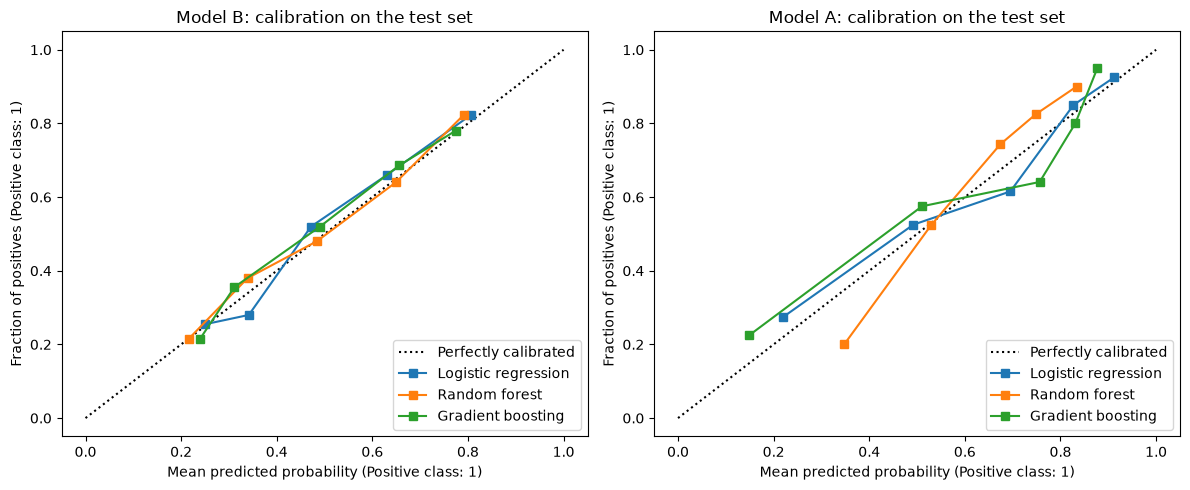

Brier score
Model B Logistic regression        0.199
        Random forest              0.203
        Gradient boosting          0.204
Model A Logistic regression        0.171
        Random forest              0.174
        Gradient boosting          0.167

In [17]:
from sklearn.calibration import CalibrationDisplay
from sklearn.metrics import brier_score_loss

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
brier = {}
for ax, (label, res) in zip(axes, [("Model B", res_B), ("Model A", res_A)]):
    for name, pipe in res["tuned"].items():
        CalibrationDisplay.from_estimator(pipe, res["X_te"], res["y_te"], n_bins=5,
                                          strategy="quantile", name=name, ax=ax)
        brier[(label, name)] = brier_score_loss(res["y_te"], pipe.predict_proba(res["X_te"])[:, 1])
    ax.set_title(f"{label}: calibration on the test set")
plt.tight_layout()
plt.show()
pd.Series(brier, name="Brier score").round(3).to_frame()

## 11. Save the model for the Streamlit app
The app model is **Model B, logistic regression** (no `work_interfere`, because the app cannot ask people how much a condition already interferes with their work). The settings were tuned and tested above on the training/test split; here the same pipeline is **refit on all 1,259 respondents** before saving, since the evaluation is finished. Saved next to it is a small JSON file with the feature list, allowed answers, cut-off and the test scores from the train-only version.

Load it with `joblib.load("../models/model_b_logreg.joblib")`; the pipeline takes a DataFrame with the columns listed in the JSON (raw answers, `Gender` already merged to Male/Female/Other, `no_employees` coded 0–5) and `predict_proba(...)[:, 1]` returns the probability of having sought treatment. Needs the same scikit-learn version as `requirements.txt`.

In [18]:
import json
from pathlib import Path

import joblib
import sklearn
from sklearn.base import clone

final_B = clone(res_B["tuned"]["Logistic regression"]).fit(X_B, y_B)

out = Path("../models")
out.mkdir(exist_ok=True)
joblib.dump(final_B, out / "model_b_logreg.joblib")

meta = {
    "model": "Logistic regression (Model B, no work_interfere)",
    "target": "1 = sought mental-health treatment",
    "threshold": 0.5,
    "trained_on_rows": int(len(X_B)),
    "sklearn_version": sklearn.__version__,
    "features": {c: (sorted(X_B[c].unique().tolist()) if X_B[c].dtype == object or str(X_B[c].dtype) == "str"
                     else [int(X_B[c].min()), int(X_B[c].max())]) for c in X_B.columns},
    "no_employees_coding": {s: i for i, s in enumerate(size_order)},
    "test_scores_train_only_fit": {k: round(v, 3) for k, v in
                                   test_scores(res_B["tuned"]["Logistic regression"], res_B["X_te"], res_B["y_te"]).items()},
    "caveat": "Associations in a 2014 survey (79% male, ~60% US); not a tool for predicting individuals.",
}
(out / "model_b_logreg.json").write_text(json.dumps(meta, indent=2))

# Round-trip check: the reloaded model must give identical probabilities
reloaded = joblib.load(out / "model_b_logreg.joblib")
assert np.allclose(reloaded.predict_proba(X_B)[:, 1], final_B.predict_proba(X_B)[:, 1])
print("Saved and verified:", sorted(p.name for p in out.iterdir()))
meta["test_scores_train_only_fit"]

Saved and verified: ['model_b_logreg.joblib', 'model_b_logreg.json']


{'AUC': 0.762,
 'F1': 0.7,
 'Recall': 0.664,
 'Precision': 0.739,
 'Accuracy': 0.71}

## 12. Conclusions and caveats
- **Model B (headline, no `work_interfere`):** cross-validated AUC is about 0.78 (random forest 0.784, logistic regression 0.776, gradient boosting 0.777, all within noise of each other), against 0.50 for the majority-class baseline. On the held-out test set it scores AUC 0.751, F1 0.688, recall 0.672, accuracy 0.690. The test score is lower than the CV score, but with only 252 test rows a gap of about 0.03 AUC is within normal sampling noise.
- **Model A (with `work_interfere`, 995 answerers):** cross-validated AUC about 0.83; test AUC 0.815, F1 0.836, recall 0.906 (gradient boosting). Its baseline is higher (63.6% of these respondents sought treatment, so always predicting "Yes" gets 63.6% accuracy), which is why its accuracy of 0.774 is a smaller gain than it looks. The gain over Model B is about 0.05 AUC, much smaller than the in-sample EDA figure of 0.907, which was inflated by scoring on training data and by keeping the "Unknown" rows.
- **No algorithm clearly wins.** Logistic, random forest and gradient boosting are within about 0.01–0.02 AUC of one another in both experiments, so the signal is simple. For explanation and for the dashboard, the logistic regression is the easier model to defend.
- **What drives Model B:** family history by far (permutation importance 0.107), then care options (0.031), gender (0.018) and benefits (0.014). This matches the EDA. In the logistic regression, family history "Yes" has an odds ratio of about 1.8 and care options "Yes" about 1.45.
- **Caveats:** the test set is small (252 and 199 rows), so single test numbers carry roughly ±0.03 AUC of uncertainty. Everything here is an association in a 2014 survey sample that is 79% male and 60% US-based; it is not a tool for predicting individuals. The 18-person "Other" gender group is too small for its own metrics. 
- **Threshold:** tuning the cut-off (Youden's J, chosen on training data only) moved Model B's cut-off to about 0.47–0.48, essentially 0.5, with a small F1 gain (logistic regression 0.700 → 0.722) that is within test-set noise. For Model A, higher cut-offs (0.54–0.67) trade recall for precision without a consistent gain in balanced accuracy. We keep **0.5** for both.
- **Calibration:** Model B's probabilities are well calibrated (predicted and actual rates track closely; Brier score 0.199 for logistic regression vs about 0.25 for always guessing the base rate). Model A's curves are rougher, but with 199 test people in 5 groups that is mostly noise (Brier 0.167–0.174 against about 0.23 for guessing the base rate).
- **Saved for the app:** Model B logistic regression, refit on all 1,259 respondents (section 11).

## 13. Simple explanation and conclusion
**What we did.** We taught three computer "guessers" (logistic regression, random forest, gradient boosting) to guess whether a tech worker sought mental-health treatment, using their other survey answers. We hid 20% of the people as a final exam and used the rest for learning and practice.

**Two versions.** *Model B* does not use the "does your condition interfere with your work?" question, because that question nearly gives the answer away. *Model A* does use it, but only for the 995 people who answered it. Model B is the main result.

**How well did they do?** (final exam)

| | Guess right | AUC (0.5 = coin flip, 1.0 = perfect) |
|---|---|---|
| Always guess the most common answer | 50.5% (B) / 63.6% (A) | 0.50 |
| Model B, best on practice: random forest | 69.0% | 0.751 |
| Model B, logistic regression | 71.0% | 0.762 |
| Model A, best: gradient boosting | 77.4% | 0.815 |

**Which is best?** None clearly. The three guessers score within about 0.02 AUC of each other, which is less than the normal wiggle for a test of only 250 people. The random forest memorized the homework (AUC 0.93 on training vs 0.75 on the test), so it is the least trustworthy. Logistic regression stayed steady and is the easiest to explain, so we prefer it for the dashboard.

**What matters most?** Family history of mental illness by a wide margin, then whether the employer offers care options, then gender and employer benefits.

**What to remember.**
- The models are clearly better than guessing, but far from perfect: about 7 in 10 guesses are right without the work-interference question.
- These are patterns in one 2014 survey (79% male, 60% US), not causes, and not a way to predict a single person.
- We also checked the Yes/No cut-off (0.5 is fine) and whether the percentages the model gives can be trusted (Model B's can). The logistic regression for Model B is saved for the dashboard.